# Canwell Glacier HRRR-AK, WY2020–WY2026

Inspect the combined hourly forecast dataset, check coverage and replacement leads, and
compare modeled weather at the grid cells nearest the five Canwell sites.

In [1]:
from pathlib import Path
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data" / "canwell_readme.txt").is_file())
path = Path(os.environ.get("CANWELL_NETCDF",
                           root / "data" / "hrrrak_canwell_f567_WY2020-WY2026.nc"))
if not path.is_file():
    raise FileNotFoundError(f"{path}. Run scripts/process_hrrrak.py from the repo root.")
ds = xr.open_dataset(path, engine="netcdf4", decode_timedelta=False)
ds

<xarray.Dataset> Size: 1GB
Dimensions:                  (time: 62832, y: 15, x: 17)
Coordinates:
  * time                     (time) datetime64[ns] 503kB 2019-08-01T05:00:00 ...
    source_water_year        (time) int16 126kB ...
    requested_forecast_hour  (time) int16 126kB ...
    forecast_reference_time  (time) datetime64[ns] 503kB ...
    forecast_hour            (time) int16 126kB ...
  * y                        (y) float64 120B -2.794e+06 ... -2.752e+06
  * x                        (x) float64 136B -5.361e+05 ... -4.881e+05
    latitude                 (y, x) float64 2kB ...
    longitude                (y, x) float64 2kB ...
Data variables: (12/17)
    crs                      int32 4B ...
    pressure                 (time, y, x) float32 64MB ...
    orog                     (time, y, x) float32 64MB ...
    temp_surface             (time, y, x) float32 64MB ...
    snowfall_total           (time, y, x) float32 64MB ...
    snow_cover               (time, y, x) float32 64MB ...
    ...                       ...
    precip_total             (time, y, x) float32 64MB ...
    precip_hourly            (time, y, x) float32 64MB ...
    tcc                      (time, y, x) float32 64MB ...
    swrad                    (time, y, x) float32 64MB ...
    lwrad                    (time, y, x) float32 64MB ...
    wind                     (time, y, x) float32 64MB ...
Attributes:
    title:        Canwell Glacier HRRR-AK forecasts, source WY2020–WY2026
    Conventions:  CF-1.10
    source:       NOAA HRRR-AK regional surface forecasts
    comment:      UTC forecast valid times. Includes WY2020 August–September ...

## Hourly coverage and source forecasts

`time` is forecast valid time in UTC. Folder water years follow the **requested initialization
date**. WY2020 includes the August–September 2019 spin-up, and September 30
initializations can verify on October 1. Replacement forecasts have shorter actual leads
and the same requested valid hour.

In [2]:
time = ds.indexes["time"]
assert time.is_unique and time.is_monotonic_increasing
expected = pd.date_range(time[0], time[-1], freq="h")
missing = expected.difference(time)
actual_lead = pd.to_timedelta(ds.forecast_hour.values, unit="h")
assert (pd.DatetimeIndex(ds.forecast_reference_time.values) + actual_lead).equals(time)
replacement = ds.forecast_hour.values != ds.requested_forecast_hour.values

print(f"{len(time):,} valid hours from {time[0]} to {time[-1]} UTC")
print(f"{len(missing):,} missing hours within this span")
if len(missing):
    display(missing[:20])

coverage = pd.DataFrame({
    "Source water year": ds.source_water_year.values,
    "Valid time (UTC)": time,
    "Replacement": replacement,
}).groupby("Source water year").agg(
    Hours=("Valid time (UTC)", "size"),
    First_valid_UTC=("Valid time (UTC)", "min"),
    Last_valid_UTC=("Valid time (UTC)", "max"),
    Replacements=("Replacement", "sum"),
)
display(coverage)

62,832 valid hours from 2019-08-01 05:00:00 to 2026-10-01 04:00:00 UTC
0 missing hours within this span


,Hours,First_valid_UTC,Last_valid_UTC,Replacements
Source water year,,,,
2020,10248,2019-08-01 05:00:00,2020-10-01 04:00:00,7
2021,8760,2020-10-01 05:00:00,2021-10-01 04:00:00,3
2022,8760,2021-10-01 05:00:00,2022-10-01 04:00:00,1
2023,8760,2022-10-01 05:00:00,2023-10-01 04:00:00,10
2024,8784,2023-10-01 05:00:00,2024-10-01 04:00:00,0
2025,8760,2024-10-01 05:00:00,2025-10-01 04:00:00,1
2026,8760,2025-10-01 05:00:00,2026-10-01 04:00:00,0


## Native grid and nearest model cells

The table pairs each station with its nearest HRRR-AK cell center. Grid geopotential
height can differ from the station elevation, especially over steep terrain.

,Site,Station elevation (m),Model geopotential height (m),y index,x index,Distance to cell center (km)
0,Canwell South Moraine Station,982.0,1042.310059,9,5,0.38
1,Look Eyrie AWS,1588.0,1205.189941,8,6,1.39
2,GPS Station Lower Canwell,1039.0,1205.189941,8,6,1.19
3,GPS Station Middle Canwell,1266.0,1470.060059,7,7,1.61
4,GPS Station Upper Canwell & (planned) Accumula...,1564.0,1926.719971,6,9,1.49


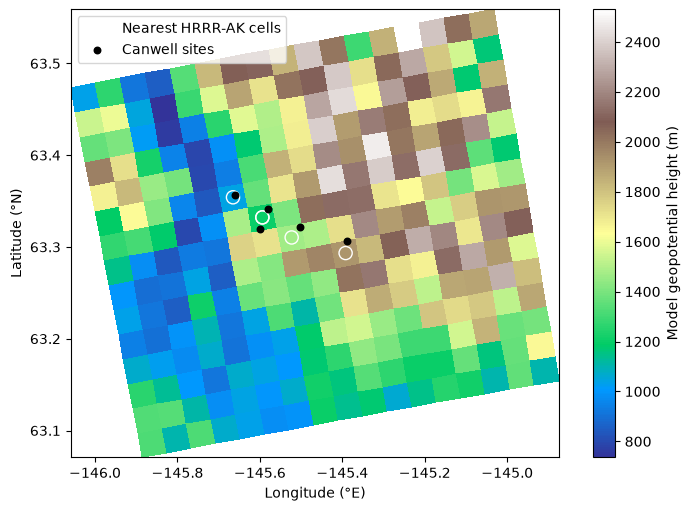

In [3]:
site_text = (root / "data" / "canwell_readme.txt").read_text()
sites = []
for block in site_text.split("### "):
    match = re.search(r"DD: ([0-9.]+),\s*(-[0-9.]+)", block)
    if match:
        name = block.split(" ###")[0].strip()
        lat, lon = map(float, match.groups())
        elevation = float(re.search(r"Elev\.: ([0-9.]+)m", block)[1])
        sites.append((name, lat, lon, elevation))

grid_lat = ds.latitude.values
grid_lon = ds.longitude.values
rows = []
for name, lat, lon, elevation in sites:
    haversine = (np.sin(np.deg2rad(grid_lat - lat) / 2)**2
                 + np.cos(np.deg2rad(lat)) * np.cos(np.deg2rad(grid_lat))
                 * np.sin(np.deg2rad(grid_lon - lon) / 2)**2)
    y, x = np.unravel_index(haversine.argmin(), grid_lat.shape)
    distance_km = 2 * 6371.229 * np.arcsin(np.sqrt(haversine[y, x]))
    rows.append((name, lat, lon, elevation, y, x, distance_km))
cells = pd.DataFrame(rows, columns=["Site", "Latitude", "Longitude", "Station elevation (m)",
                                    "y index", "x index", "Distance to cell center (km)"])
point = ds.isel(y=xr.DataArray(cells["y index"].values, dims="site"),
                x=xr.DataArray(cells["x index"].values, dims="site"))
cells["Model geopotential height (m)"] = point.orog.isel(time=0).values
display(cells[["Site", "Station elevation (m)", "Model geopotential height (m)",
               "y index", "x index", "Distance to cell center (km)"]].round(2))

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
mesh = ax.pcolormesh(grid_lon, grid_lat, ds.orog.isel(time=0), shading="nearest", cmap="terrain")
fig.colorbar(mesh, ax=ax, label="Model geopotential height (m)")
ax.scatter(point.longitude, point.latitude, facecolors="none", edgecolors="white",
           s=90, label="Nearest HRRR-AK cells")
ax.scatter(cells.Longitude, cells.Latitude, s=22, c="black", label="Canwell sites")
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       aspect=1 / np.cos(np.deg2rad(grid_lat.mean())))
ax.legend(loc="upper left")
plt.show()

## Hourly weather at Look Eyrie AWS

The temperature, wind and precipitation come from the nearest model cell. Daily precipitation
sums `precip_hourly` across 24 one-hour intervals ending at midnight UTC. The variable
`precip_total` accumulates from each forecast's actual initialization and has overlapping
windows across consecutive forecast hours.

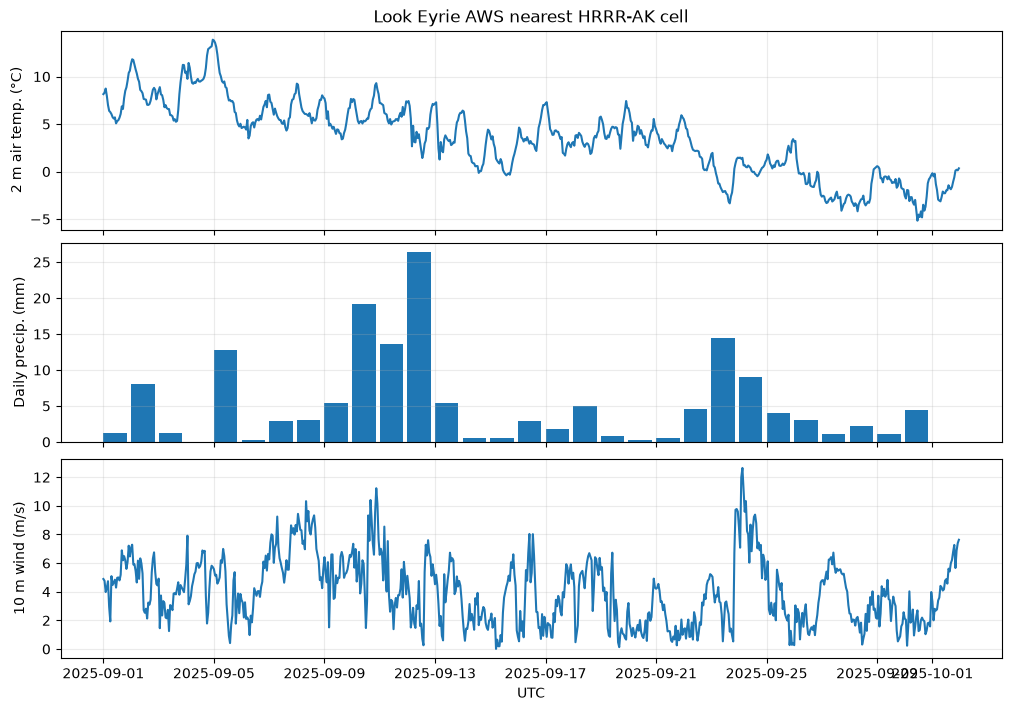

In [4]:
site = cells.index[cells.Site.eq("Look Eyrie AWS")][0]
start, end = "2025-09-01", "2025-10-01"
sample = point[["temp", "precip_hourly", "wind"]].isel(site=site).sel(time=slice(start, end)).load()
# Bin interval-ending timestamps into the UTC day where the precipitation fell.
daily_precip = sample.precip_hourly.resample(time="1D", closed="right").sum(
    skipna=True, min_count=24
).dropna("time")

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 7), layout="constrained")
axes[0].plot(sample.time, sample.temp - 273.15)
axes[0].set(ylabel="2 m air temp. (°C)", title="Look Eyrie AWS nearest HRRR-AK cell")
axes[1].bar(daily_precip.time.values, daily_precip.values, align="edge", width=0.85)
axes[1].set(ylabel="Daily precip. (mm)")
axes[2].plot(sample.time, sample.wind)
axes[2].set(ylabel="10 m wind (m/s)", xlabel="UTC")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

## Look Eyrie AWS · WY2025 SNOWPACK forcing

Hourly HRRR-AK forcing at the grid cell nearest Look Eyrie, from October 1, 2024 through September 30, 2025 UTC. The subplot titles give the NetCDF variable, full name, and units written to SMET. The y-axes give the SMET fields. The values use the Canwell forcing script's conversions. Wind direction is shown as points because it wraps at 360°. Precipitation is the one-hour amount ending at each timestamp.

Nearest HRRR-AK cell (y, x) = (8, 6), 1.39 km away, elevation 1205.2 m


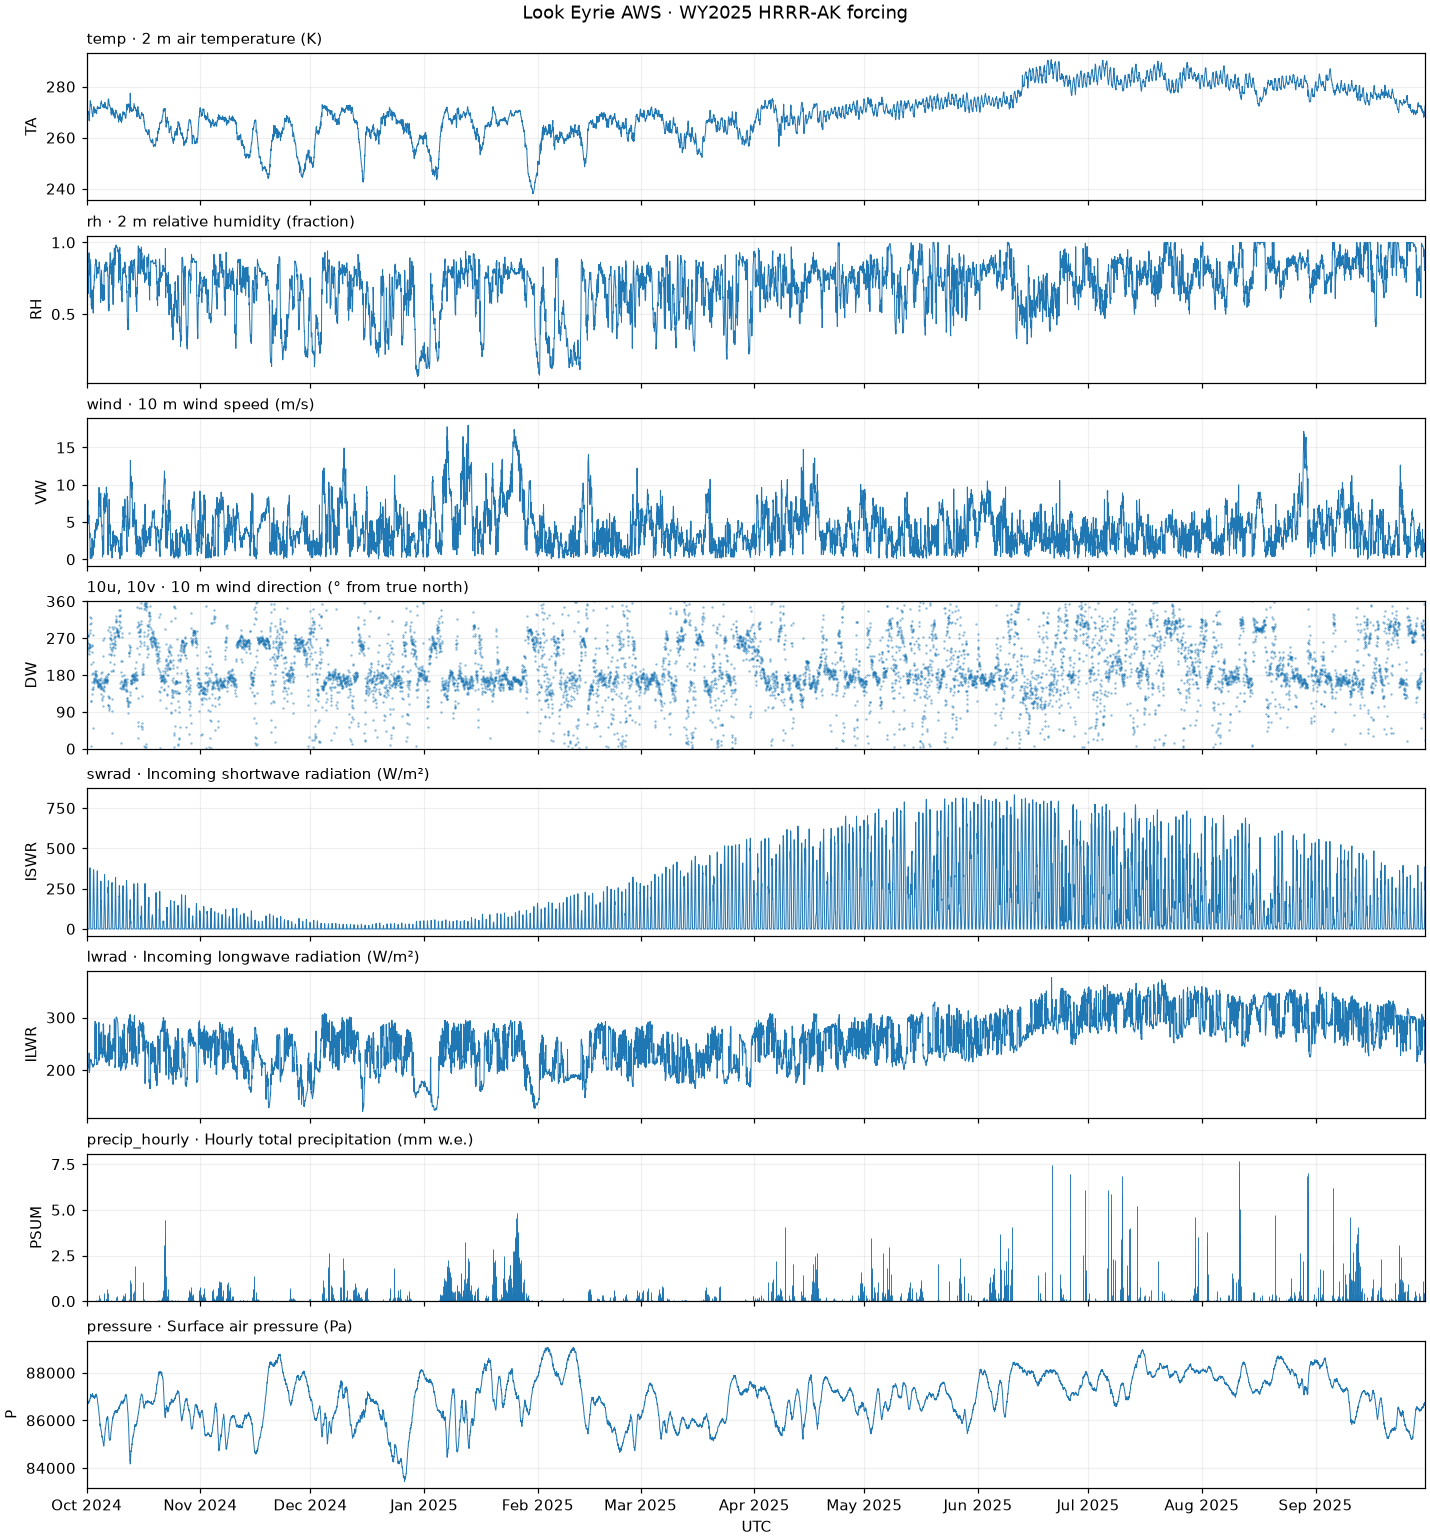

In [ ]:
import sys
import matplotlib.dates as mdates

sys.path.insert(0, str(root / "scripts"))
from create_snowpack_forcing import hrrr_forcing, station_location

location = station_location(root / "data" / "look_eyrie")
forcing = hrrr_forcing(path, location)
hours = pd.date_range("2024-10-01", "2025-10-01", freq="h", tz="UTC", inclusive="left")
wy2025 = forcing.reindex(hours)

fields = {
    "TA": ("temp", "2 m air temperature", "K"),
    "RH": ("rh", "2 m relative humidity", "fraction"),
    "VW": ("wind", "10 m wind speed", "m/s"),
    "DW": ("10u, 10v", "10 m wind direction", "° from true north"),
    "ISWR": ("swrad", "Incoming shortwave radiation", "W/m²"),
    "ILWR": ("lwrad", "Incoming longwave radiation", "W/m²"),
    "PSUM": ("precip_hourly", "Hourly total precipitation", "mm w.e."),
    "P": ("pressure", "Surface air pressure", "Pa"),
}

fig_wy2025, forcing_axes = plt.subplots(
    len(fields), 1, sharex=True, figsize=(13, 14), layout="constrained"
)
for ax, (field, (variable, description, unit)) in zip(forcing_axes, fields.items()):
    values = wy2025[field]
    if field == "DW":
        ax.plot(values.index, values, ".", markersize=1, alpha=0.55)
        ax.set(ylim=(0, 360), yticks=[0, 90, 180, 270, 360])
    elif field == "PSUM":
        precip = values[values > 0]
        ax.vlines(precip.index, 0, precip, linewidth=0.6)
        ax.set_ylim(bottom=0)
    else:
        ax.plot(values.index, values, linewidth=0.65)
    ax.set_ylabel(field)
    ax.set_title(f"{variable} · {description} ({unit})", loc="left", fontsize=10)
    ax.grid(alpha=0.2)

forcing_axes[-1].xaxis.set_major_locator(mdates.MonthLocator(tz="UTC"))
forcing_axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y", tz="UTC"))
forcing_axes[-1].set(xlim=(hours[0], hours[-1]), xlabel="UTC")
fig_wy2025.suptitle("Look Eyrie AWS · WY2025 HRRR-AK forcing")
plt.show()
